# Métricas e diagnóstico — CV/OOF e TEST separados
Este notebook lê os artefatos reais produzidos pelo script de treino. A seleção usa
**AP média da CV temporal no TRAIN**; a classe positiva é **fraude (1)**.
AP é calculada sobre probabilidades, não rótulos, e não é a integral trapezoidal de PR.
Threshold fixo **0,5** para todas as receitas; nenhum ajuste no TEST.
Dummy é baseline ingênuo; há apenas duas famílias de modelos treináveis.

## Como interpretar as métricas

As tabelas abaixo têm rótulos descritivos. Percentuais são apenas uma forma de
exibir os valores: **0,000190 = 0,0190%**. Os CSVs conservam valores numéricos.

| Métrica | Pergunta que responde / denominador |
|---|---|
| Taxa de fraude na faixa | Entre as transações dessa faixa, quantas são fraude? = 100 × fraudes / transações da faixa. Não é erro do modelo. |
| Parcela das fraudes do TRAIN | Entre todas as fraudes do TRAIN, quantas estão nessa faixa? |
| Recall | Entre as fraudes reais, quantas o modelo detectou? = TP/(TP+FN). |
| Precision | Entre os alertas, quantos eram fraude real? = TP/(TP+FP). |
| F1 | Média harmônica de Precision e Recall, com peso simétrico. |
| F2 | Média harmônica que favorece Recall; objetivo das rodadas posteriores. |
| FP / FN | FP é legítima alertada; FN é fraude não detectada. TP/TN são acertos de fraude/legítima. |
| Taxa de falsos positivos | FP/(FP+TN): fração das legítimas que gerou alerta. |
| Parcela de alertas falsos | FP/(FP+TP) = 1−Precision. Tem denominador diferente da taxa de falsos positivos. |
| AP / curva PR | AP resume a curva Precision–Recall usando probabilidades; maior é melhor. Não equivale à área trapezoidal PR. |
| ROC-AUC | Resumo de ordenação fraude versus legítima; complementar à AP para classe rara. |
| Log Loss / Brier | Erros das probabilidades: menor é melhor. Não comprovam calibração. |
| Média e desvio de CV | Resumo entre folds temporais; desvio não é intervalo de confiança. |
| Correlação / importância | Correlação é associação com Class; importância de permutação é queda de AP na validação interna. Escalas distintas e sem causalidade. |

Se um segmento não tiver fraudes ou alertas, certas taxas ficam **Não definido**:
isso não significa taxa zero. Não some categorias de features distintas:
as mesmas transações reaparecem em cada feature.

Veja [o guia completo das métricas](../docs/metrics_guide.md), incluindo fórmulas,
unidades, outliers/IQR, assimetria, cardinalidade, diversidade OOF, threshold,
StandardScaler, SMOTE e limitações da validação.

In [1]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists():
    ROOT = ROOT.parent
if not (ROOT / "pyproject.toml").exists():
    raise RuntimeError("Abra o notebook pela raiz do projeto ou pela pasta notebooks.")
METRICS = ROOT / "reports/metrics"
FIGURES = ROOT / "reports/figures"
EXPERIMENTS = ROOT / "reports/experiments"

def table(name, **kwargs):
    path = METRICS / name
    if not path.exists():
        raise FileNotFoundError(f"Artefato ausente: {path.name}. Execute os scripts conforme README.")
    return pd.read_csv(path, **kwargs)

def figure(name, width=1000):
    path = FIGURES / name
    if not path.exists():
        raise FileNotFoundError(f"Figura ausente: {path.name}. Execute os scripts conforme README.")
    display(Image(filename=str(path), width=width))

# Mantém os cálculos numéricos; traduz unidades e rótulos apenas ao exibir a tabela.
from fraud_detection.reporting import readable_table

def display_readable(frame):
    display(readable_table(frame))


## Comparação em CV no TRAIN
Mesmos folds e mesma política de threshold. As barras são médias dos folds; erros mostram desvio-padrão descritivo.

,Receita,Origem,Limiar de alerta,AP (score),average_precision_std,F1 (%),F1 desvio (p.p.),Recall (%),Recall desvio (p.p.),Precision (%),Precision desvio (p.p.),ROC-AUC (score),roc_auc_std,Balanced Accuracy (%),Balanced Accuracy desvio (p.p.)
0,xgboost__none,CV temporal TRAIN,"0,5000","0,7689","0,0208",77.19%,2.34 p.p.,69.96%,7.09 p.p.,87.67%,11.23 p.p.,"0,9700","0,0193",84.97%,3.54 p.p.
1,random_forest__none,CV temporal TRAIN,"0,5000","0,7580","0,0325",77.78%,1.47 p.p.,67.93%,5.24 p.p.,91.80%,7.28 p.p.,"0,9390","0,0434",83.96%,2.62 p.p.
2,random_forest__under_smote,CV temporal TRAIN,"0,5000","0,7513","0,0354",58.22%,21.90 p.p.,80.40%,5.88 p.p.,50.87%,30.88 p.p.,"0,9661","0,0264",90.13%,2.90 p.p.
3,xgboost__under_smote,CV temporal TRAIN,"0,5000","0,7387","0,0084",35.40%,26.94 p.p.,83.19%,7.78 p.p.,26.76%,25.46 p.p.,"0,9661","0,0165",91.25%,3.71 p.p.
4,dummy,CV temporal TRAIN,"0,5000","0,0014","0,0006",0.00%,0.00 p.p.,0.00%,0.00 p.p.,0.00%,0.00 p.p.,"0,5000","0,0000",50.00%,0.00 p.p.


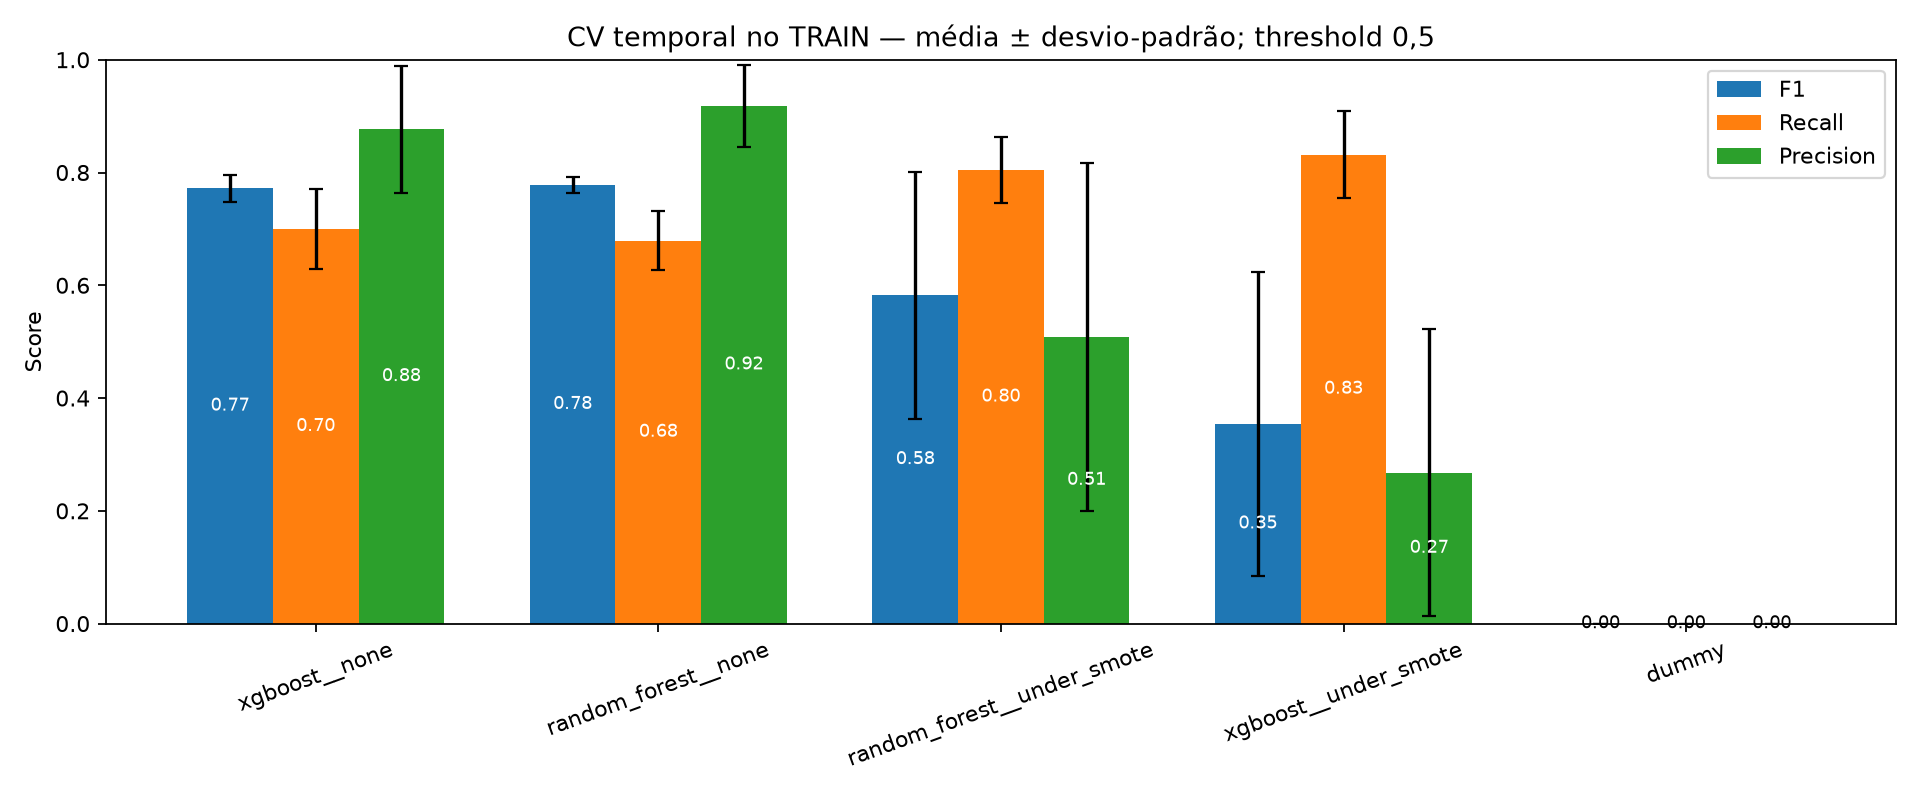

A receita selecionada por CV foi **xgboost__none**, com AP média **0.7689 ± 0.0208**. A seleção entre receitas pode favorecer otimisticamente o vencedor; o TEST é relatado só ao final.

In [2]:
comparison = table("model_comparison.csv")
display_readable(comparison.drop(columns="configuration"))
figure("model_comparison_f1_recall_precision.png", 1100)
best = comparison.iloc[0]
display(Markdown(f"A receita selecionada por CV foi **{best.model}**, com AP média **{best.average_precision:.4f} ± {best.average_precision_std:.4f}**. A seleção entre receitas pode favorecer otimisticamente o vencedor; o TEST é relatado só ao final."))

## Folds, estabilidade e generalização
Separar scores de treino e validação ajuda a examinar sobreajuste. O tamanho cresce e o período muda entre folds, portanto este gráfico não é uma learning curve controlada.

,Fold temporal,fit_rows,validation_rows,fit_positive,validation_positive,fit_time_max,validation_time_min,validation_time_max
0,1,45.840,58.589,143,84,"42.612,0000","42.613,0000","69.254,0000"
1,2,104.429,51.704,227,105,"69.254,0000","69.255,0000","108.793,0000"
2,3,156.133,54.159,332,44,"108.793,0000","108.799,0000","138.230,0000"


,Receita,Fold temporal,Origem,AP (score),F1 (%),Recall (%),Precision (%),ROC-AUC (score),Balanced Accuracy (%),Especificidade (%),Log Loss,Brier score,TN: legítimas liberadas,FP: falsos alertas,FN: fraudes não detectadas,TP: fraudes detectadas,Limiar de alerta,train_average_precision,train_f1,train_recall,train_precision,train_roc_auc,train_balanced_accuracy
0,dummy,1,CV temporal TRAIN,"0,0014",0.00%,0.00%,0.00%,"0,5000",50.00%,100.00%,"0,0114","0,0014",58.505,0,84,0,"0,5000","0,0031",0.00%,0.00%,0.00%,"0,5000",50.00%
1,dummy,2,CV temporal TRAIN,"0,0020",0.00%,0.00%,0.00%,"0,5000",50.00%,100.00%,"0,0146","0,0020",51.599,0,105,0,"0,5000","0,0022",0.00%,0.00%,0.00%,"0,5000",50.00%
2,dummy,3,CV temporal TRAIN,"0,0008",0.00%,0.00%,0.00%,"0,5000",50.00%,100.00%,"0,0071","0,0008",54.115,0,44,0,"0,5000","0,0021",0.00%,0.00%,0.00%,"0,5000",50.00%
3,random_forest__none,1,CV temporal TRAIN,"0,7736",76.47%,61.90%,100.00%,"0,8893",80.95%,100.00%,"0,0120","0,0005",58.505,0,32,52,"0,5000","0,9989",98.96%,100.00%,97.95%,"1,0000",100.00%
4,random_forest__none,2,CV temporal TRAIN,"0,7799",79.37%,71.43%,89.29%,"0,9695",85.71%,99.98%,"0,0069","0,0007",51.590,9,30,75,"0,5000","0,9972",98.70%,100.00%,97.42%,"1,0000",100.00%
5,random_forest__none,3,CV temporal TRAIN,"0,7206",77.50%,70.45%,86.11%,"0,9580",85.22%,99.99%,"0,0049","0,0004",54.110,5,13,31,"0,5000","0,9945",98.08%,100.00%,96.23%,"1,0000",100.00%
6,xgboost__none,1,CV temporal TRAIN,"0,7689",76.47%,61.90%,100.00%,"0,9478",80.95%,100.00%,"0,0036","0,0005",58.505,0,32,52,"0,5000","0,9935",97.86%,95.80%,100.00%,"1,0000",97.90%
7,xgboost__none,2,CV temporal TRAIN,"0,7897",79.80%,75.24%,84.95%,"0,9805",87.61%,99.97%,"0,0037","0,0007",51.585,14,26,79,"0,5000","0,9817",95.39%,91.19%,100.00%,"0,9999",95.59%
8,xgboost__none,3,CV temporal TRAIN,"0,7482",75.29%,72.73%,78.05%,"0,9818",86.36%,99.98%,"0,0021","0,0003",54.106,9,12,32,"0,5000","0,9720",93.08%,89.16%,97.37%,"0,9998",94.58%
9,random_forest__under_smote,1,CV temporal TRAIN,"0,7613",79.25%,75.00%,84.00%,"0,9358",87.49%,99.98%,"0,0174","0,0017",58.493,12,21,63,"0,5000","0,8438",83.87%,100.00%,72.22%,"0,9997",99.94%


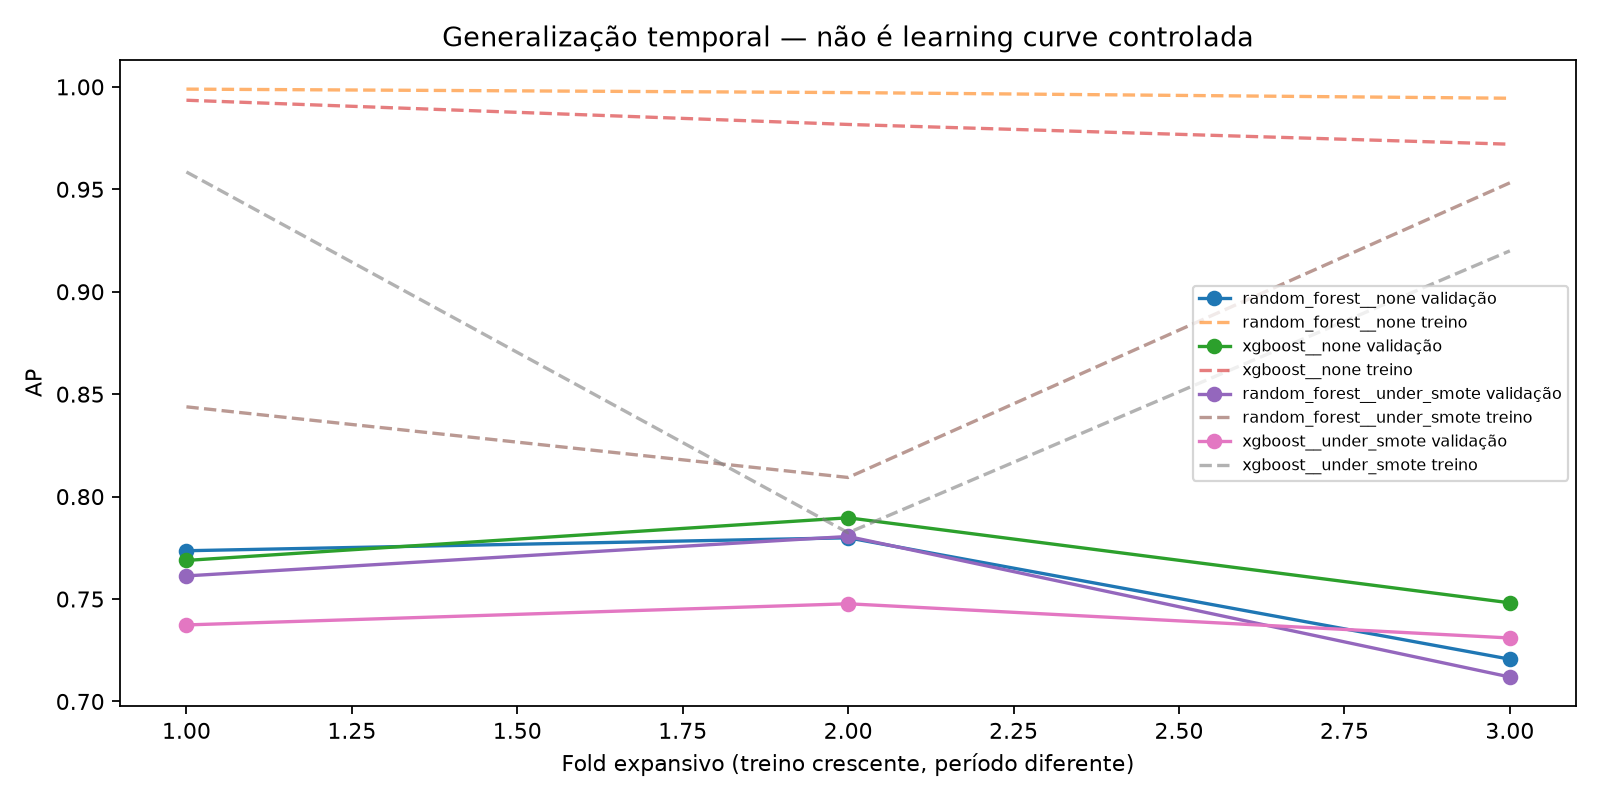

A AP de validação da receita selecionada varia de **0.7482** a **0.7897** entre janelas. Diferenças treino–validação combinam ajuste do modelo e mudança temporal; não demonstram isoladamente alto viés ou variância.

In [3]:
folds = table("cv_folds.csv")
display_readable(pd.read_csv(EXPERIMENTS / "fold_manifest.csv"))
display_readable(folds)
figure("train_validation.png")
spread = folds[folds.model == best.model].average_precision
display(Markdown(f"A AP de validação da receita selecionada varia de **{spread.min():.4f}** a **{spread.max():.4f}** entre janelas. Diferenças treino–validação combinam ajuste do modelo e mudança temporal; não demonstram isoladamente alto viés ou variância."))

## Número de árvores no XGBoost
Curvas na última janela de validação do TRAIN com números de árvores prefixados. Servem para diagnóstico; não houve retuning ou early stopping nesta execução. Early stopping em uma rodada futura exige validação interna ao treino de cada fold e nunca o TEST.

,Receita,trees,TRAIN_fold,validation_TRAIN
0,xgboost__none,10,"0,8279","0,7067"
1,xgboost__none,25,"0,8516","0,7184"
2,xgboost__none,50,"0,8868","0,7381"
3,xgboost__none,100,"0,9263","0,7464"
4,xgboost__none,200,"0,9720","0,7482"
5,xgboost__under_smote,10,"0,7511","0,7189"
6,xgboost__under_smote,25,"0,7624","0,7283"
7,xgboost__under_smote,50,"0,8275","0,7478"
8,xgboost__under_smote,100,"0,8622","0,7400"
9,xgboost__under_smote,200,"0,9199","0,7310"


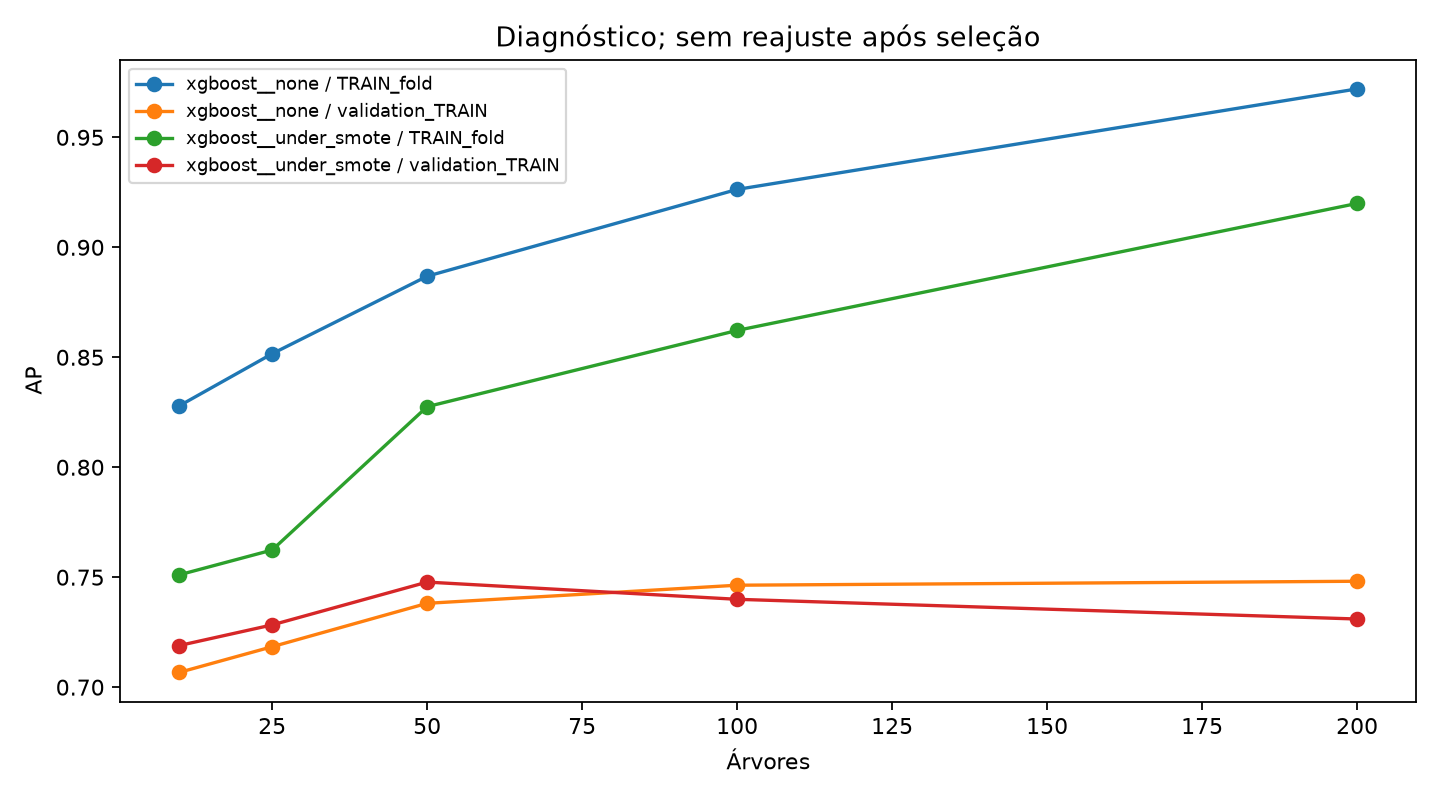

Observe se a AP de validação estabiliza enquanto a de treino continua subindo. Os valores não foram usados para reajustar o número de árvores nesta rodada.

In [4]:
display_readable(table("boosting_iterations.csv"))
figure("boosting_iterations.png")
display(Markdown("Observe se a AP de validação estabiliza enquanto a de treino continua subindo. Os valores não foram usados para reajustar o número de árvores nesta rodada."))

## OOF temporal: cobertura parcial e erros complementares
O prefixo inicial só treina e não recebe previsão OOF. As demais amostras são previstas por modelos treinados no passado. AP agregada OOF não é a média das APs dos folds.

Cobertura OOF: **164,452** linhas (**78.2%** do TRAIN).

,Receita,Origem,AP (score),F1 (%),Recall (%),Precision (%),ROC-AUC (score),Balanced Accuracy (%),Especificidade (%),Log Loss,Brier score,TN: legítimas liberadas,FP: falsos alertas,FN: fraudes não detectadas,TP: fraudes detectadas,Limiar de alerta
0,dummy,"OOF temporal TRAIN (agregado, cobertura parcial)","0,0016",0.00%,0.00%,0.00%,"0,5467",50.00%,100.00%,"0,0110","0,0014",164.219,0,233,0,"0,5000"
1,random_forest__none,"OOF temporal TRAIN (agregado, cobertura parcial)","0,7555",78.02%,67.81%,91.86%,"0,9344",83.90%,99.99%,"0,0081","0,0005",164.205,14,75,158,"0,5000"
2,xgboost__none,"OOF temporal TRAIN (agregado, cobertura parcial)","0,7518",77.80%,69.96%,87.63%,"0,9608",84.97%,99.99%,"0,0032","0,0005",164.196,23,70,163,"0,5000"
3,random_forest__under_smote,"OOF temporal TRAIN (agregado, cobertura parcial)","0,7454",57.27%,81.12%,44.26%,"0,9490",90.49%,99.86%,"0,0478","0,0063",163.981,238,44,189,"0,5000"
4,xgboost__under_smote,"OOF temporal TRAIN (agregado, cobertura parcial)","0,6994",25.26%,83.69%,14.87%,"0,9490",91.51%,99.32%,"0,0294","0,0062",163.103,1.116,38,195,"0,5000"


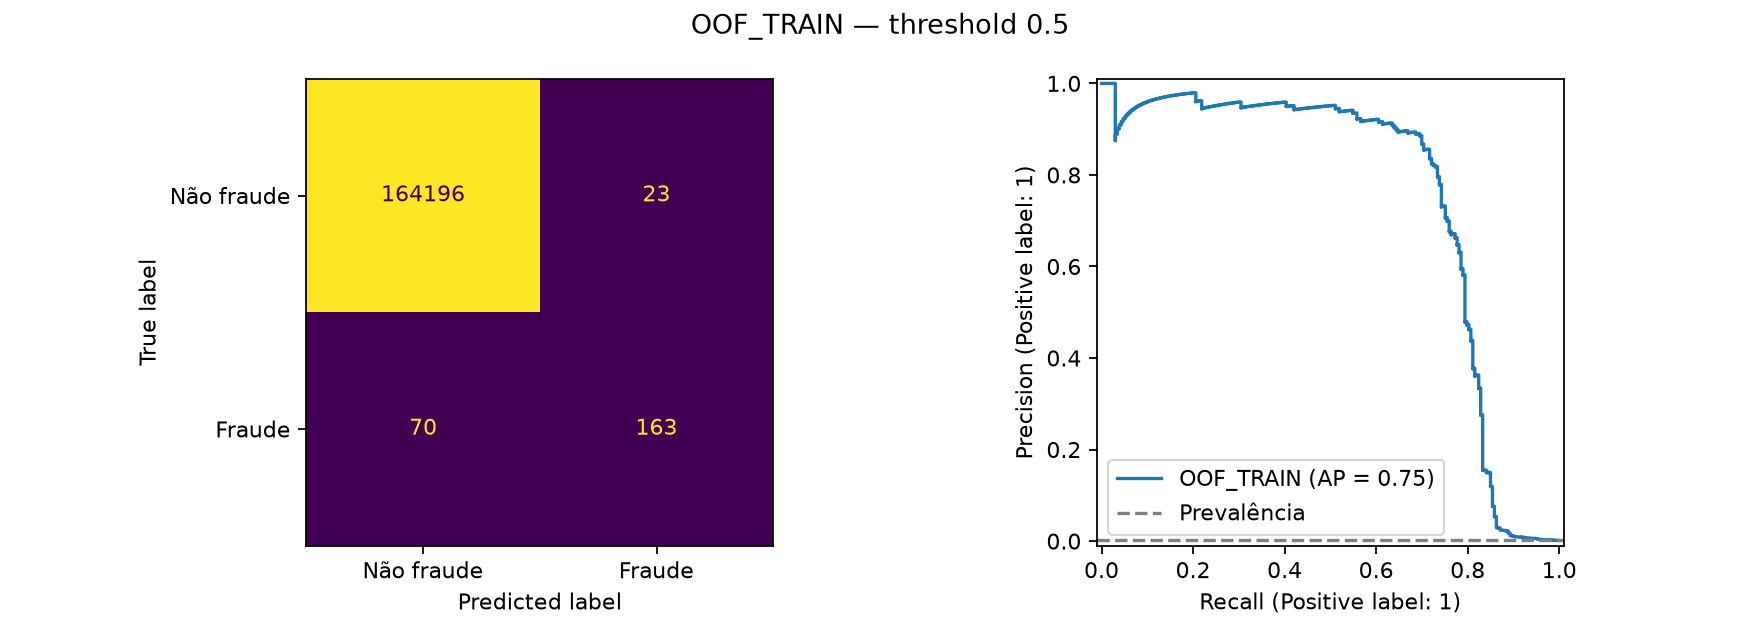

,model_a,model_b,disagreement,double_fault,both_correct,only_a_wrong,only_b_wrong
0,random_forest__none,xgboost__none,0.02%,0.05%,99.94%,0.01%,0.01%
1,random_forest__none,random_forest__under_smote,0.16%,0.04%,99.81%,0.02%,0.14%
2,random_forest__none,xgboost__under_smote,0.69%,0.03%,99.28%,0.02%,0.67%
3,xgboost__none,random_forest__under_smote,0.15%,0.04%,99.81%,0.02%,0.13%
4,xgboost__none,xgboost__under_smote,0.68%,0.04%,99.28%,0.02%,0.66%
5,random_forest__under_smote,xgboost__under_smote,0.56%,0.16%,99.28%,0.02%,0.55%


Double-fault mede a fração em que ambos erram; disagreement mede predições diferentes. Discordância, sozinha, não prova benefício de Voting/Stacking. Não foi incluído ensemble sem validação adicional.

In [5]:
manifest = json.loads((EXPERIMENTS / "run_manifest.json").read_text(encoding="utf-8"))
display(Markdown(f"Cobertura OOF: **{manifest['oof_rows']:,}** linhas (**{manifest['oof_coverage']:.1%}** do TRAIN)."))
display_readable(table("oof_metrics.csv"))
figure("OOF_TRAIN_diagnostics.png")
display_readable(table("error_diversity.csv"))
display(Markdown("Double-fault mede a fração em que ambos erram; disagreement mede predições diferentes. Discordância, sozinha, não prova benefício de Voting/Stacking. Não foi incluído ensemble sem validação adicional."))

## Associação versus importância
Correlação no TRAIN completo; permutação (queda de AP) na última validação do TRAIN, sem ajuste do estimador nessa janela. A seleção do vencedor já usou essa validação: interpretação condicionada à seleção. Os painéis têm **escalas distintas**.

,Feature,Pearson com Class,Spearman com Class,Queda de AP por permutação,Desvio da permutação,Importância interna da árvore
14,V14,"-0,3091","-0,0659","0,2438","0,0189","0,2099"
4,V4,"0,1389","0,0640","0,1041","0,0175","0,0267"
10,V10,"-0,2366","-0,0614","0,0659","0,0021","0,3075"
7,V7,"-0,2106","-0,0497","0,0277","0,0054","0,0098"
12,V12,"-0,2624","-0,0644","0,0217","0,0161","0,0376"
16,V16,"-0,2159","-0,0519","0,0157","0,0023","0,0663"
17,V17,"-0,3597","-0,0453","0,0148","0,0032","0,1286"
8,V8,"0,0406","0,0240","0,0109","0,0050","0,0095"
28,V28,"0,0082","0,0197","0,0105","0,0038","0,0086"
3,V3,"-0,2197","-0,0610","0,0085","0,0034","0,0184"


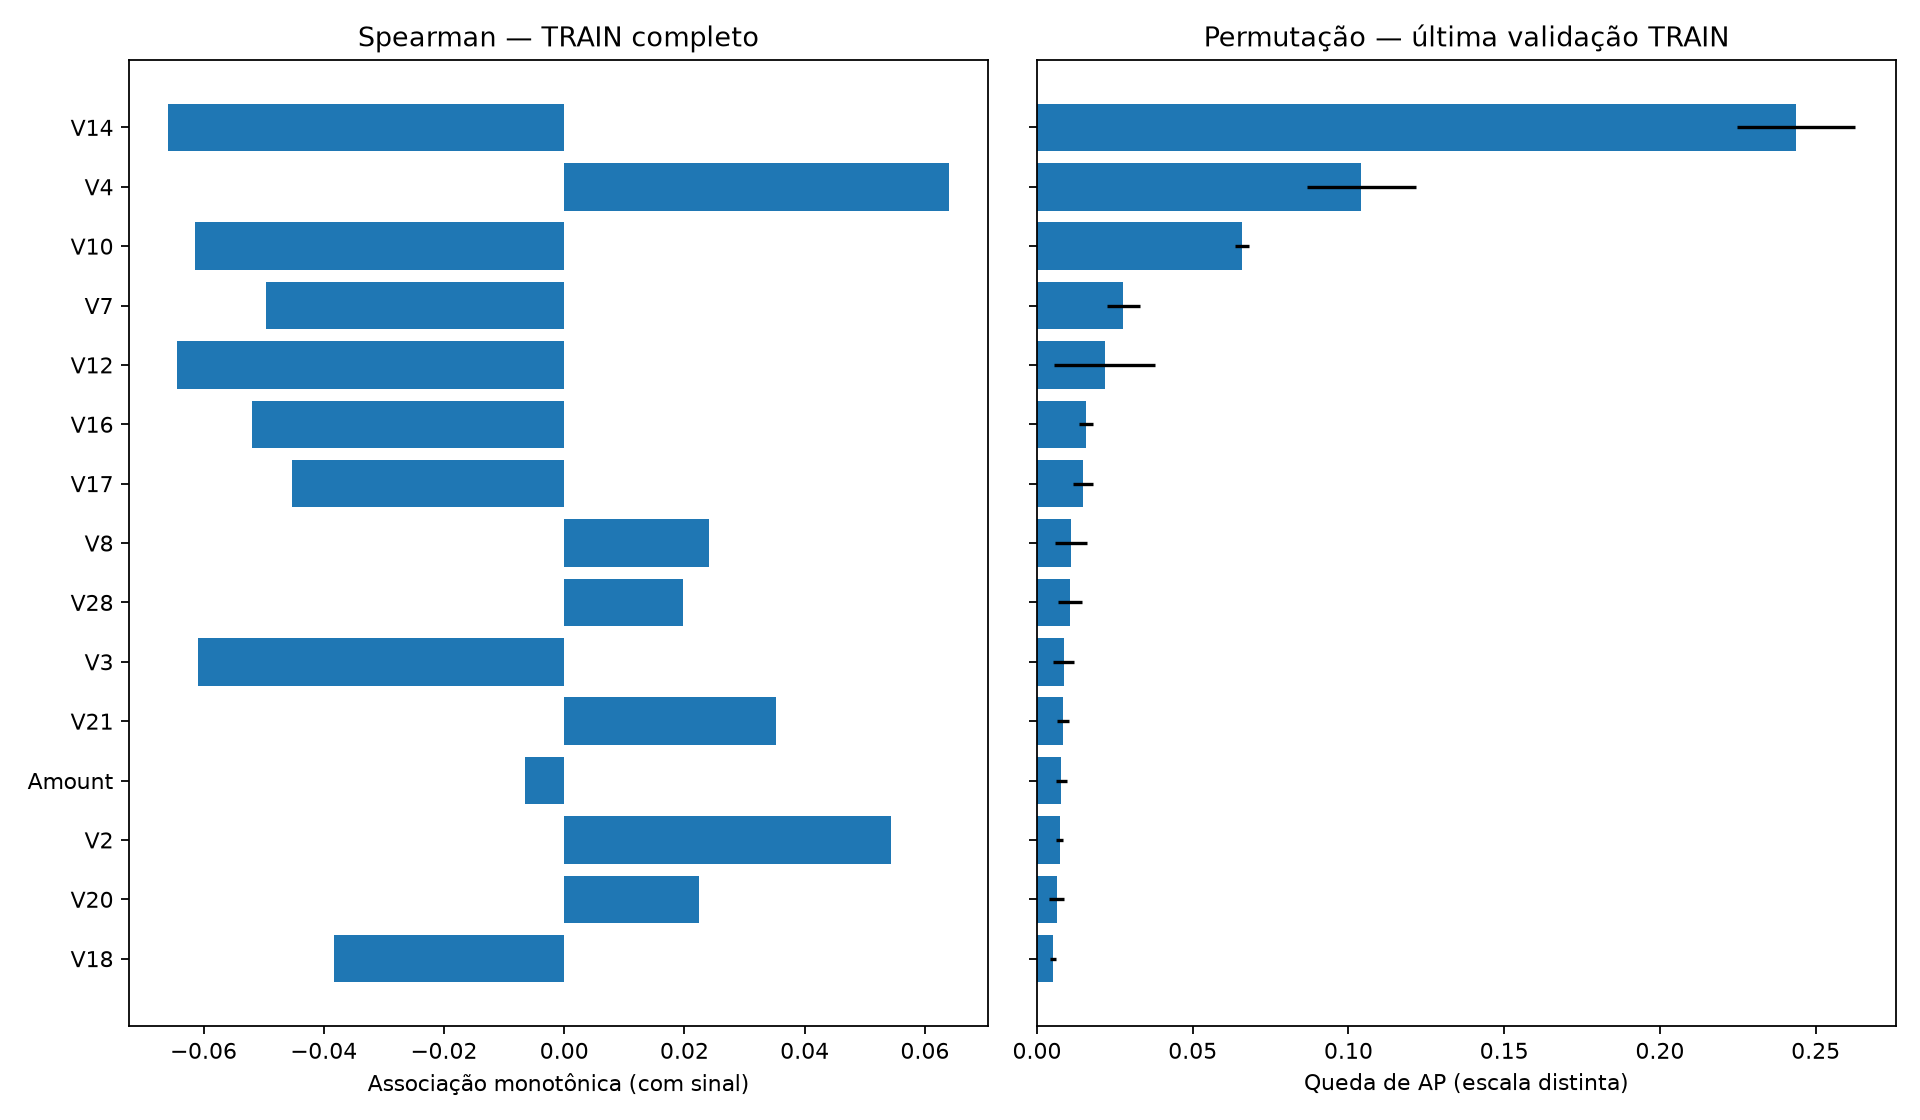

Spearman captura monotonicidade; permutação mede contribuição preditiva no pipeline. Importâncias de árvore também estão na tabela e podem favorecer certos atributos ou dividir crédito entre correlacionados. Correlação e importância não provam causalidade; não houve remoção de features com base nesses valores.

In [6]:
association = table("association_importance.csv")
display_readable(association.sort_values("permutation_ap", ascending=False))
figure("association_importance.png")
display(Markdown("Spearman captura monotonicidade; permutação mede contribuição preditiva no pipeline. Importâncias de árvore também estão na tabela e podem favorecer certos atributos ou dividir crédito entre correlacionados. Correlação e importância não provam causalidade; não houve remoção de features com base nesses valores."))

## Conclusões da seleção e limitações
A seleção foi congelada em selection.json antes de avaliar TEST. Pesos e reamostragem definem receitas distintas; não se isolou causalmente o efeito do SMOTE. Não houve calibração, busca extensa ou escolha de threshold operacional. O manifesto abaixo registra decisões e limites, sem expor transações.

In [7]:
display({k: v for k, v in manifest.items() if not k.startswith("test_")})
display(json.loads((EXPERIMENTS / "selection.json").read_text(encoding="utf-8")))

{'dataset_sha256': '76274b691b16a6c49d3f159c883398e03ccd6d1ee12d9d8ee38f4b4b98551a89',
 'dataset_file': 'creditcard.csv',
 'config': {'data_path': 'data/raw/creditcard.csv',
  'seed': 42,
  'test_time_fraction': 0.2,
  'cv_splits': 3,
  'threshold': 0.5,
  'primary_metric': 'average_precision',
  'n_jobs': 2,
  'sampling_strategies': ['none', 'under_smote'],
  'under_ratio': 0.1,
  'smote_ratio': 0.6,
  'smote_neighbors': 3,
  'models': {'random_forest': {'n_estimators': 160,
    'max_depth': 14,
    'min_samples_leaf': 2,
    'max_features': 'sqrt',
    'criterion': 'gini',
    'class_weight': 'balanced_subsample'},
   'xgboost': {'n_estimators': 200,
    'max_depth': 4,
    'learning_rate': 0.05,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'reg_alpha': 0.0,
    'reg_lambda': 1.0,
    'min_child_weight': 3}}},
 'versions': {'numpy': '2.5.4',
  'pandas': '2.3.3',
  'scikit-learn': '1.7.2',
  'imbalanced-learn': '0.14.2',
  'xgboost': '3.4.1',
  'matplotlib': '3.11.2'},
 'cut

{'model': 'xgboost__none',
 'selection': 'maior AP média em CV temporal TRAIN',
 'threshold': 0.5,
 'config': {'data_path': 'data/raw/creditcard.csv',
  'seed': 42,
  'test_time_fraction': 0.2,
  'cv_splits': 3,
  'threshold': 0.5,
  'primary_metric': 'average_precision',
  'n_jobs': 2,
  'sampling_strategies': ['none', 'under_smote'],
  'under_ratio': 0.1,
  'smote_ratio': 0.6,
  'smote_neighbors': 3,
  'models': {'random_forest': {'n_estimators': 160,
    'max_depth': 14,
    'min_samples_leaf': 2,
    'max_features': 'sqrt',
    'criterion': 'gini',
    'class_weight': 'balanced_subsample'},
   'xgboost': {'n_estimators': 200,
    'max_depth': 4,
    'learning_rate': 0.05,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'reg_alpha': 0.0,
    'reg_lambda': 1.0,
    'min_child_weight': 3}}},
 'features': ['Time',
  'V1',
  'V2',
  'V3',
  'V4',
  'V5',
  'V6',
  'V7',
  'V8',
  'V9',
  'V10',
  'V11',
  'V12',
  'V13',
  'V14',
  'V15',
  'V16',
  'V17',
  'V18',
  'V19',
  'V2

## Nova rodada — GridSearchCV de threshold com ênfase em Recall
A comparação inicial acima usa threshold 0,5. Nesta rodada posterior,
a receita XGBoost sem reamostragem permanece fixa. GridSearchCV busca
**F2 (beta=2)** em 29 limiares, com Recall favorecido e Precision ainda relevante.

Cada treino de fold externo é separado cronologicamente em subtreino e janela
interna de threshold. O pipeline aprende no subtreino; FrozenEstimator o mantém
congelado enquanto GridSearchCV varia o threshold do FixedThresholdClassifier.
O pipeline é então reajustado no treino externo e a política é avaliada no fold
externo posterior. A tabela abaixo separa essa avaliação do score interno usado
para seleção. **TEST não foi avaliado novamente.**

A receita havia sido selecionada usando os mesmos dados: esta avaliação é
condicionada à receita e não elimina o viés da seleção anterior.

,Receita,Política de threshold,Origem,F2 (%),F2 desvio (p.p.),Recall (%),Recall desvio (p.p.),Precision (%),Precision desvio (p.p.),F1 (%),F1 desvio (p.p.),AP (score),average_precision_std,Taxa de alertas (%),Taxa de alertas desvio (p.p.),FP: falsos alertas,fp_std,FN: fraudes não detectadas,fn_std
0,xgboost__none,fixed_0.5,CV externa temporal TRAIN,72.58%,5.09 p.p.,69.96%,7.09 p.p.,87.67%,11.23 p.p.,77.19%,2.34 p.p.,"0,7689","0,0208",0.11%,0.06 p.p.,"7,6667","7,0946","23,3333","10,2632"
1,xgboost__none,gridsearch_f2,CV externa temporal TRAIN,76.34%,1.56 p.p.,76.95%,4.18 p.p.,75.86%,13.15 p.p.,75.79%,4.44 p.p.,"0,7689","0,0208",0.15%,0.08 p.p.,"20,3333","16,9214","17,6667","6,8069"


,Fold temporal,Receita,Política de threshold,Origem,AP (score),F1 (%),Recall (%),Precision (%),ROC-AUC (score),Balanced Accuracy (%),Especificidade (%),Log Loss,Brier score,TN: legítimas liberadas,FP: falsos alertas,FN: fraudes não detectadas,TP: fraudes detectadas,Limiar de alerta,F2 (%),alerts,Taxa de alertas (%)
0,1,xgboost__none,fixed_0.5,CV temporal externa TRAIN; threshold ajustado internamente,"0,7689",76.47%,61.90%,100.00%,"0,9478",80.95%,100.00%,"0,0036","0,0005",58.505,0,32,52,"0,5000",67.01%,52,0.09%
1,1,xgboost__none,gridsearch_f2,CV temporal externa TRAIN; threshold ajustado internamente,"0,7689",80.79%,72.62%,91.04%,"0,9478",86.30%,99.99%,"0,0036","0,0005",58.499,6,23,61,"0,1000",75.68%,67,0.11%
2,2,xgboost__none,fixed_0.5,CV temporal externa TRAIN; threshold ajustado internamente,"0,7897",79.80%,75.24%,84.95%,"0,9805",87.61%,99.97%,"0,0037","0,0007",51.585,14,26,79,"0,5000",77.00%,93,0.18%
3,2,xgboost__none,gridsearch_f2,CV temporal externa TRAIN; threshold ajustado internamente,"0,7897",74.24%,80.95%,68.55%,"0,9805",90.44%,99.92%,"0,0037","0,0007",51.560,39,20,85,"0,1750",78.12%,124,0.24%
4,3,xgboost__none,fixed_0.5,CV temporal externa TRAIN; threshold ajustado internamente,"0,7482",75.29%,72.73%,78.05%,"0,9818",86.36%,99.98%,"0,0021","0,0003",54.106,9,12,32,"0,5000",73.73%,41,0.08%
5,3,xgboost__none,gridsearch_f2,CV temporal externa TRAIN; threshold ajustado internamente,"0,7482",72.34%,77.27%,68.00%,"0,9818",88.62%,99.97%,"0,0021","0,0003",54.099,16,10,34,"0,4000",75.22%,50,0.09%


,outer_fold,Limiar de alerta,cutoff_time,duplicates_removed,inner_fit_rows,inner_tune_rows,inner_fit_time_max,inner_tune_time_min,inner_tune_time_max,inner_tune_positives,outer_fit_rows,outer_validation_rows,outer_fit_time_max,outer_validation_time_min,outer_validation_time_max
0,1,"0,1000","34.089,6000",0,26.374,19.466,"34.089,0000","34.090,0000","42.612,0000",55,45.840,58.589,"42.612,0000","42.613,0000","69.254,0000"
1,2,"0,1750","55.403,2000",0,73.767,30.662,"55.403,0000","55.404,0000","69.254,0000",47,104.429,51.704,"69.254,0000","69.255,0000","108.793,0000"
2,3,"0,4000","87.034,4000",0,144.990,11.143,"87.034,0000","87.035,0000","108.793,0000",60,156.133,54.159,"108.793,0000","108.799,0000","138.230,0000"


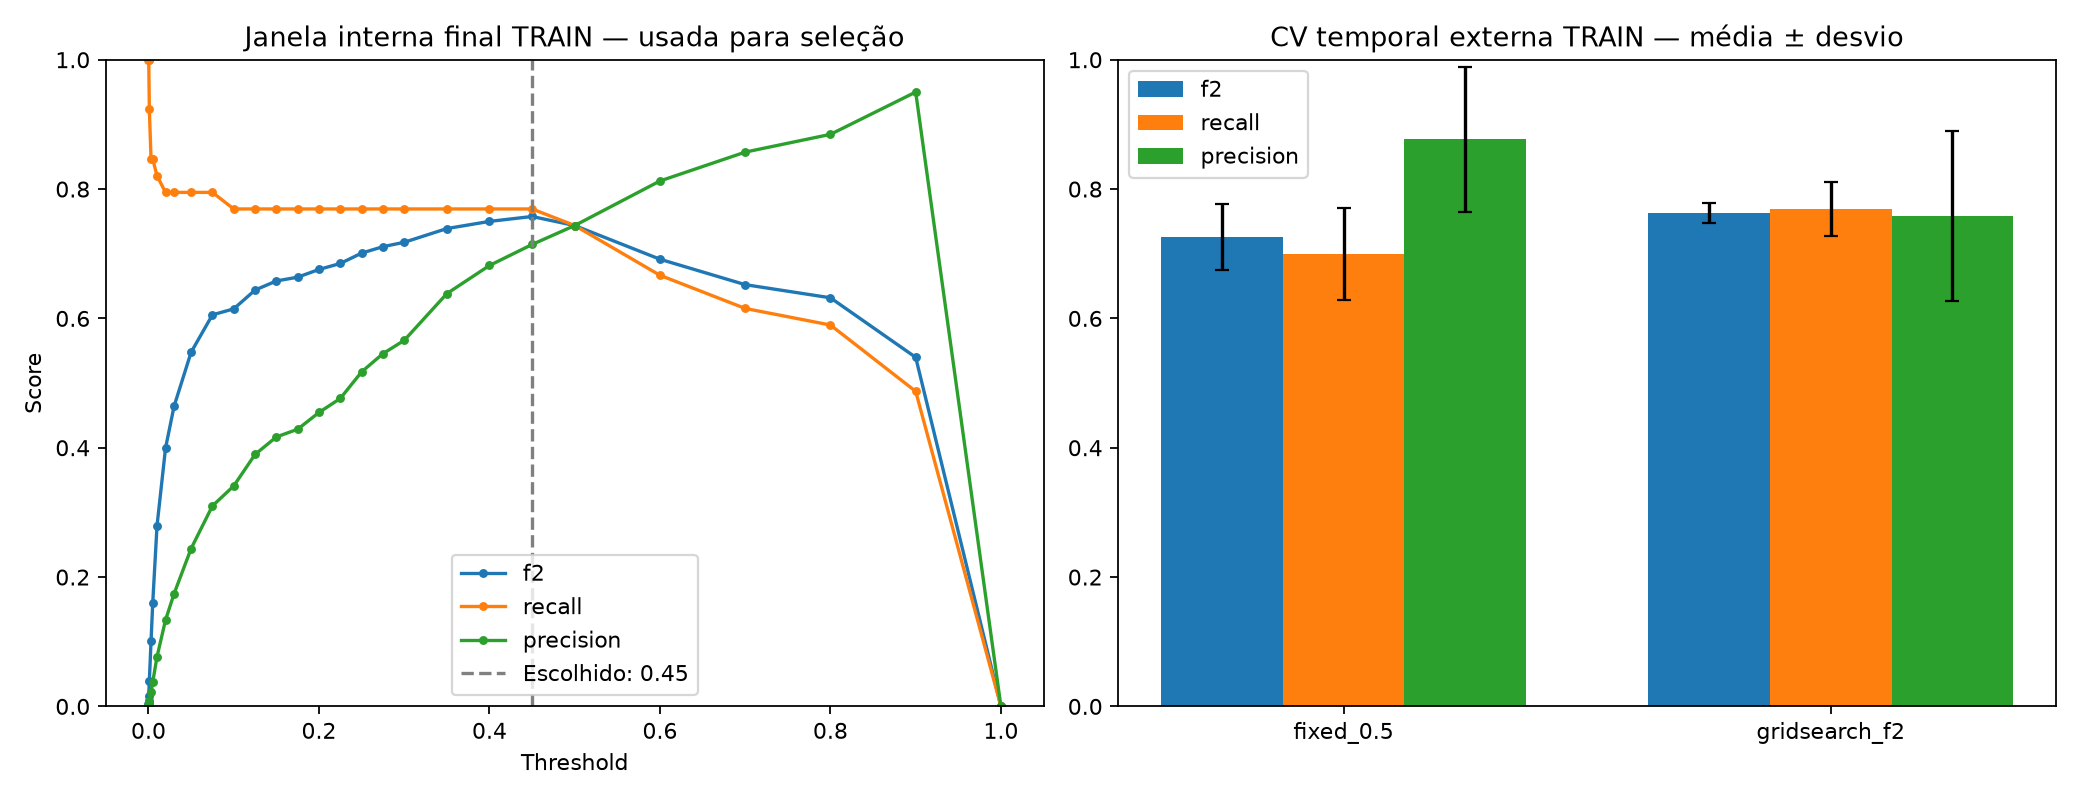

Na CV temporal externa, Recall médio passou de **0.700** para **0.769**, Precision de **0.877** para **0.759**, e F2 de **0.726** para **0.763**. Os folds escolhem seus próprios thresholds.

In [8]:
threshold_selection = json.loads(
    (EXPERIMENTS / "threshold_selection.json").read_text(encoding="utf-8")
)
threshold_comparison = table("threshold_comparison.csv")
display_readable(threshold_comparison)
display_readable(table("threshold_outer_folds.csv"))
display_readable(pd.read_csv(EXPERIMENTS / "threshold_folds.csv"))
figure("threshold_recall_f2.png", 1100)
baseline = threshold_comparison.set_index("policy").loc["fixed_0.5"]
tuned = threshold_comparison.set_index("policy").loc["gridsearch_f2"]
display(Markdown(
    f"Na CV temporal externa, Recall médio passou de **{baseline.recall:.3f}** "
    f"para **{tuned.recall:.3f}**, Precision de **{baseline.precision:.3f}** "
    f"para **{tuned.precision:.3f}**, e F2 de **{baseline.f2:.3f}** "
    f"para **{tuned.f2:.3f}**. Os folds escolhem seus próprios thresholds."
))

### Limiar final e fronteira Recall–Precision
O limiar final é pesquisado novamente no TRAIN, sem consultar TEST. A tabela
de grade abaixo vem da janela interna final: seus scores são de **seleção**,
não uma estimativa independente de desempenho do artefato final.

In [9]:
display_readable(table("threshold_grid.csv"))
display(threshold_selection)
display(Markdown(
    f"Melhor threshold F2 nesta grade: **{threshold_selection['threshold']:g}**. "
    "O pipeline foi reajustado em todo o TRAIN e salvo em "
    "**models/recall_pipeline.joblib**. Esse limiar ainda precisa ser avaliado "
    "em um período externo novo."
))
raw_recall = threshold_selection["recall_only_reference"]
display(Markdown(
    f"Recall puro escolheria **{raw_recall['threshold']:g}** na janela interna, "
    f"com Recall **{raw_recall['recall']:.3f}**, "
    f"Precision **{raw_recall['precision']:.4f}** e "
    f"**{int(raw_recall['alerts']):,} alertas**. Por isso adotamos F2."
))

,Limiar de alerta,F2 (%),Recall (%),Precision (%),F1 (%),Taxa de alertas (%),alerts,TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas
0,"0,0000",0.37%,100.00%,0.07%,0.15%,100.00%,53.008,39,52.969,0
1,"0,0001",0.77%,100.00%,0.15%,0.31%,47.70%,25.287,39,25.248,0
2,"0,0003",1.63%,100.00%,0.33%,0.66%,22.31%,11.826,39,11.787,0
3,"0,0010",3.89%,92.31%,0.81%,1.60%,8.43%,4.466,36,4.430,3
4,"0,0030",10.11%,84.62%,2.24%,4.36%,2.78%,1.476,33,1.443,6
5,"0,0050",16.03%,84.62%,3.78%,7.24%,1.65%,873,33,840,6
6,"0,0100",27.92%,82.05%,7.67%,14.04%,0.79%,417,32,385,7
7,"0,0200",39.95%,79.49%,13.36%,22.88%,0.44%,232,31,201,8
8,"0,0300",46.41%,79.49%,17.42%,28.57%,0.34%,178,31,147,8
9,"0,0500",54.77%,79.49%,24.41%,37.35%,0.24%,127,31,96,8


{'model': 'xgboost__none',
 'threshold': 0.45,
 'objective': 'F2',
 'positive_class': 1,
 'settings': {'model': 'xgboost__none',
  'objective': 'f2',
  'beta': 2.0,
  'inner_validation_time_fraction': 0.2,
  'thresholds': [0.0,
   0.0001,
   0.0003,
   0.001,
   0.003,
   0.005,
   0.01,
   0.02,
   0.03,
   0.05,
   0.075,
   0.1,
   0.125,
   0.15,
   0.175,
   0.2,
   0.225,
   0.25,
   0.275,
   0.3,
   0.35,
   0.4,
   0.45,
   0.5,
   0.6,
   0.7,
   0.8,
   0.9,
   1.0]},
 'experiment_config': {'data_path': 'data/raw/creditcard.csv',
  'seed': 42,
  'test_time_fraction': 0.2,
  'cv_splits': 3,
  'threshold': 0.5,
  'primary_metric': 'average_precision',
  'n_jobs': 2,
  'sampling_strategies': ['none', 'under_smote'],
  'under_ratio': 0.1,
  'smote_ratio': 0.6,
  'smote_neighbors': 3,
  'models': {'random_forest': {'n_estimators': 160,
    'max_depth': 14,
    'min_samples_leaf': 2,
    'max_features': 'sqrt',
    'criterion': 'gini',
    'class_weight': 'balanced_subsample'},
  

Melhor threshold F2 nesta grade: **0.45**. O pipeline foi reajustado em todo o TRAIN e salvo em **models/recall_pipeline.joblib**. Esse limiar ainda precisa ser avaliado em um período externo novo.

Recall puro escolheria **0.0003** na janela interna, com Recall **1.000**, Precision **0.0033** e **11,826 alertas**. Por isso adotamos F2.

## Nova ablação — StandardScaler, SMOTE e retirada conjunta
Dez receitas com Random Forest/XGBoost, nos mesmos três folds temporais.
A comparação inicial desta rodada usa **threshold 0,5 em todas as receitas**.
Isso evita confundir ganho de scaling/seleção/SMOTE com mudança de threshold.

A regra remove a feature **somente se |Pearson| < 0,090 E queda de AP por
permutação < 0,100**. A importância usa referência XGBoost numa janela interna
ao treino de cada fold. Uma correlação negativa forte mantém a feature.
A versão final respeita a retirada solicitada, enquanto os controles com todas
as features permitem medir o custo/ganho da regra.

SMOTE usa razão minoria/maioria 0,1, após padronização, mantendo todas as legítimas.
RF sem SMOTE usa pesos de classe; com SMOTE usa pesos uniformes. Assim comparamos
receitas completas, não isolamos causalmente só o efeito do sampler.
SMOTENC não se aplica: as entradas são numéricas; os bins dos relatórios não são
novas variáveis categóricas do modelo. **TEST não foi reavaliado.**

,Receita,F2 (%),F2 desvio (p.p.),Recall (%),Recall desvio (p.p.),Precision (%),Precision desvio (p.p.),F1 (%),AP (score),FP: falsos alertas,FN: fraudes não detectadas
0,random_forest__scaled_smote_all,77.83%,2.78 p.p.,77.11%,2.03 p.p.,82.38%,14.13 p.p.,79.20%,"0,7603","11,3333","17,6667"
1,random_forest__scaled_smote_selected,77.51%,2.53 p.p.,76.31%,3.32 p.p.,83.74%,10.31 p.p.,79.55%,"0,7557","10,3333","18,3333"
2,random_forest__scaled_selected,74.20%,5.58 p.p.,71.23%,7.32 p.p.,90.55%,6.81 p.p.,79.32%,"0,7590","5,6667","23,0000"
3,xgboost__raw_all,72.58%,5.09 p.p.,69.96%,7.09 p.p.,87.67%,11.23 p.p.,77.19%,"0,7689","7,6667","23,3333"
4,xgboost__scaled_all,72.58%,5.09 p.p.,69.96%,7.09 p.p.,87.67%,11.23 p.p.,77.19%,"0,7689","7,6667","23,3333"
5,xgboost__scaled_selected,72.11%,8.69 p.p.,69.00%,10.51 p.p.,90.68%,8.99 p.p.,77.64%,"0,7684","5,3333","24,0000"
6,random_forest__raw_all,71.51%,3.95 p.p.,67.93%,5.24 p.p.,91.80%,7.28 p.p.,77.78%,"0,7580","4,6667","25,0000"
7,random_forest__scaled_all,71.51%,3.95 p.p.,67.93%,5.24 p.p.,91.80%,7.28 p.p.,77.78%,"0,7581","4,6667","25,0000"
8,xgboost__scaled_smote_selected,69.33%,10.94 p.p.,76.00%,7.58 p.p.,62.23%,32.01 p.p.,64.42%,"0,7646","45,0000","18,3333"
9,xgboost__scaled_smote_all,68.68%,7.00 p.p.,74.37%,7.74 p.p.,62.80%,29.17 p.p.,64.41%,"0,7571","40,6667","20,3333"


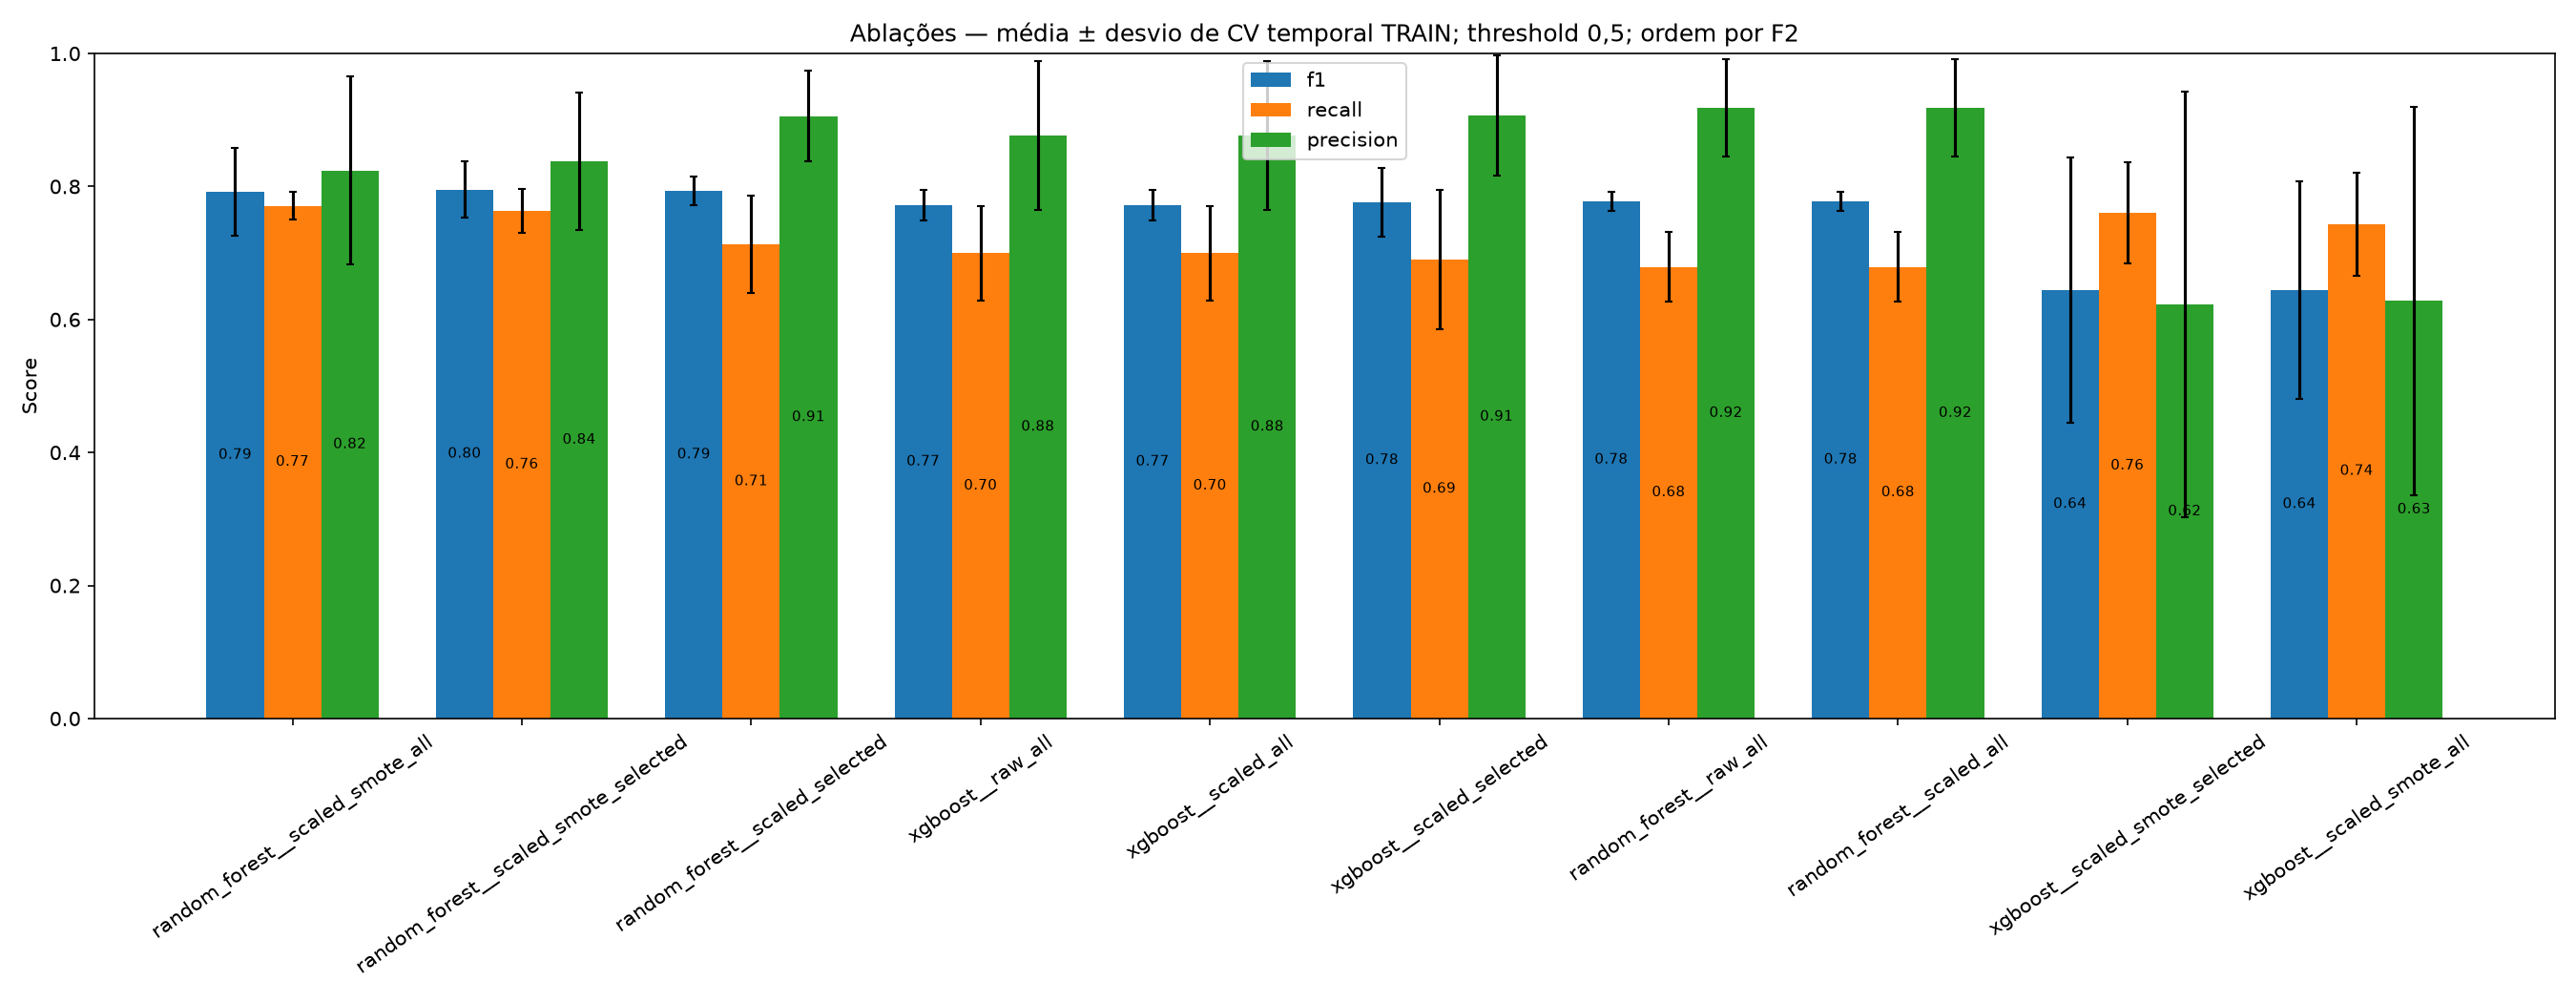

Maior F2 geral: **random_forest__scaled_smote_all**. Versão filtrada: **random_forest__scaled_smote_selected**. Se a versão completa vencer, a retirada não deve ser descrita como melhoria.

In [10]:
ablation = table("ablation_comparison.csv")
display_readable(ablation[
    ["model", "f2", "f2_std", "recall", "recall_std", "precision",
     "precision_std", "f1", "average_precision", "fp", "fn"]
])
figure("ablation_f1_recall_precision.png", 1200)
ablation_selection = json.loads(
    (EXPERIMENTS / "ablation_selection.json").read_text(encoding="utf-8")
)
display(Markdown(
    f"Maior F2 geral: **{ablation_selection['best_overall_cv']}**. "
    f"Versão filtrada: **{ablation_selection['model']}**. "
    "Se a versão completa vencer, a retirada não deve ser descrita como melhoria."
))

### Features mantidas e retiradas
Os cortes foram solicitados, não descobertos como ótimos. A seleção é reaprendida
em cada treino: o conjunto pode mudar por fold. O refit final reaprende a regra
no TRAIN completo. As duas condições precisam ser verdadeiras para retirar;
igualdade ao corte mantém a variável.

In [11]:
# A tabela explicita as duas condições; o modelo usa somente as features mantidas.
display_readable(table("feature_selection_final.csv")[
    ["feature", "pearson", "abs_pearson", "permutation_ap",
     "permutation_std", "keep", "remove"]
])
display_readable(table("feature_selection_folds.csv")[
    ["fold", "feature", "pearson", "permutation_ap", "keep"]
])
display(Markdown(
    "**Mantidas:** " + ", ".join(ablation_selection["selected_features"]) + "."
))
display(Markdown(
    "**Retiradas:** " + ", ".join(ablation_selection["removed_features"]) + "."
))

,Feature,Pearson com Class,|Pearson|,Queda de AP por permutação,Desvio da permutação,Manter?,Remover?
0,Time,"-0,0140","0,0140","0,0000","0,0000",False,True
1,V1,"-0,1153","0,1153","0,0050","0,0024",True,False
2,V2,"0,1017","0,1017","-0,0016","0,0025",True,False
3,V3,"-0,2197","0,2197","0,0113","0,0077",True,False
4,V4,"0,1389","0,1389","0,1117","0,0140",True,False
5,V5,"-0,1154","0,1154","-0,0053","0,0018",True,False
6,V6,"-0,0475","0,0475","-0,0003","0,0023",False,True
7,V7,"-0,2106","0,2106","0,0252","0,0027",True,False
8,V8,"0,0406","0,0406","0,0199","0,0058",False,True
9,V9,"-0,1007","0,1007","0,0002","0,0014",True,False


,Fold temporal,Feature,Pearson com Class,Queda de AP por permutação,Manter?
0,1,Time,"-0,0059","0,0000",False
1,1,V1,"-0,2266","0,0001",True
2,1,V2,"0,1936","0,0027",True
3,1,V3,"-0,4149","-0,0001",True
4,1,V4,"0,2342","0,0206",True
5,1,V5,"-0,2200","0,0001",True
6,1,V6,"-0,1033","0,0013",True
7,1,V7,"-0,3541","0,0001",True
8,1,V8,"0,1765","0,0009",True
9,1,V9,"-0,1743","-0,0004",True


**Mantidas:** V1, V2, V3, V4, V5, V7, V9, V10, V11, V12, V14, V16, V17, V18.

**Retiradas:** Time, V6, V8, V13, V15, V19, V20, V21, V22, V23, V24, V25, V26, V27, V28, Amount.

### Threshold F2 da receita filtrada e erros por segmento
Dentro de cada treino externo, seleção e threshold são recalculados no subtreino
e janela interna antes da validação externa. A receita já foi escolhida usando
os mesmos folds; estes diagnósticos são condicionados à escolha e podem ser
otimistas. O threshold final não foi avaliado em TEST novo.

Na tabela por faixa: taxa de fraude descreve os rótulos; FPR mede falsas acusações
entre legítimas; parcela de alertas falsos usa os alertas como denominador.
As faixas são aprendidas no treino do fold. Poucos eventos tornam taxas instáveis.

Nesta rodada, o ajuste interno aumentou Recall externo, mas reduziu Precision e
**não melhorou F2 externo** (0,7741 contra 0,7751 com limiar fixo 0,5).
O threshold 0,7 é o vencedor da grade interna final, não um limiar comprovadamente
superior em dados novos. Não há garantia de melhoria simultânea das duas métricas.

,Política de threshold,Origem,F2 (%),F2 desvio (p.p.),F1 (%),F1 desvio (p.p.),Recall (%),Recall desvio (p.p.),Precision (%),Precision desvio (p.p.),AP (score),average_precision_std,Taxa de alertas (%),Taxa de alertas desvio (p.p.),FP: falsos alertas,fp_std,FN: fraudes não detectadas,fn_std
0,fixed_0.5,CV temporal externa TRAIN,77.51%,2.53 p.p.,79.55%,4.22 p.p.,76.31%,3.32 p.p.,83.74%,10.31 p.p.,"0,7557","0,0370",0.13%,0.05 p.p.,"10,3333","4,6188","18,3333","7,2342"
1,gridsearch_f2,CV temporal externa TRAIN,77.41%,1.35 p.p.,75.02%,5.03 p.p.,79.41%,4.67 p.p.,72.24%,12.45 p.p.,"0,7557","0,0370",0.17%,0.10 p.p.,"27,6667","26,3122","15,3333","5,0332"


,Fold temporal,Política de threshold,Receita,Origem,AP (score),F1 (%),Recall (%),Precision (%),ROC-AUC (score),Balanced Accuracy (%),Especificidade (%),Log Loss,Brier score,TN: legítimas liberadas,FP: falsos alertas,FN: fraudes não detectadas,TP: fraudes detectadas,Limiar de alerta,F2 (%),alerts,Taxa de alertas (%)
0,1,fixed_0.5,random_forest__scaled_smote_selected,CV temporal externa TRAIN; receita condicionada à seleção,"0,7752",81.33%,72.62%,92.42%,"0,9216",86.31%,99.99%,"0,0081","0,0005",58.500,5,23,61,"0,5000",75.87%,66,0.11%
1,1,gridsearch_f2,random_forest__scaled_smote_selected,CV temporal externa TRAIN; receita condicionada à seleção,"0,7752",80.50%,76.19%,85.33%,"0,9216",88.09%,99.98%,"0,0081","0,0005",58.494,11,20,64,"0,3000",77.86%,75,0.13%
2,2,fixed_0.5,random_forest__scaled_smote_selected,CV temporal externa TRAIN; receita condicionada à seleção,"0,7788",82.59%,79.05%,86.46%,"0,9764",89.51%,99.97%,"0,0079","0,0009",51.586,13,22,83,"0,5000",80.43%,96,0.19%
3,2,gridsearch_f2,random_forest__scaled_smote_selected,CV temporal externa TRAIN; receita condicionada à seleção,"0,7788",70.63%,84.76%,60.54%,"0,9764",92.32%,99.89%,"0,0079","0,0009",51.541,58,16,89,"0,3000",78.48%,147,0.28%
4,3,fixed_0.5,random_forest__scaled_smote_selected,CV temporal externa TRAIN; receita condicionada à seleção,"0,7130",74.73%,77.27%,72.34%,"0,9775",88.62%,99.98%,"0,0109","0,0009",54.102,13,10,34,"0,5000",76.23%,47,0.09%
5,3,gridsearch_f2,random_forest__scaled_smote_selected,CV temporal externa TRAIN; receita condicionada à seleção,"0,7130",73.91%,77.27%,70.83%,"0,9775",88.62%,99.97%,"0,0109","0,0009",54.101,14,10,34,"0,4500",75.89%,48,0.09%


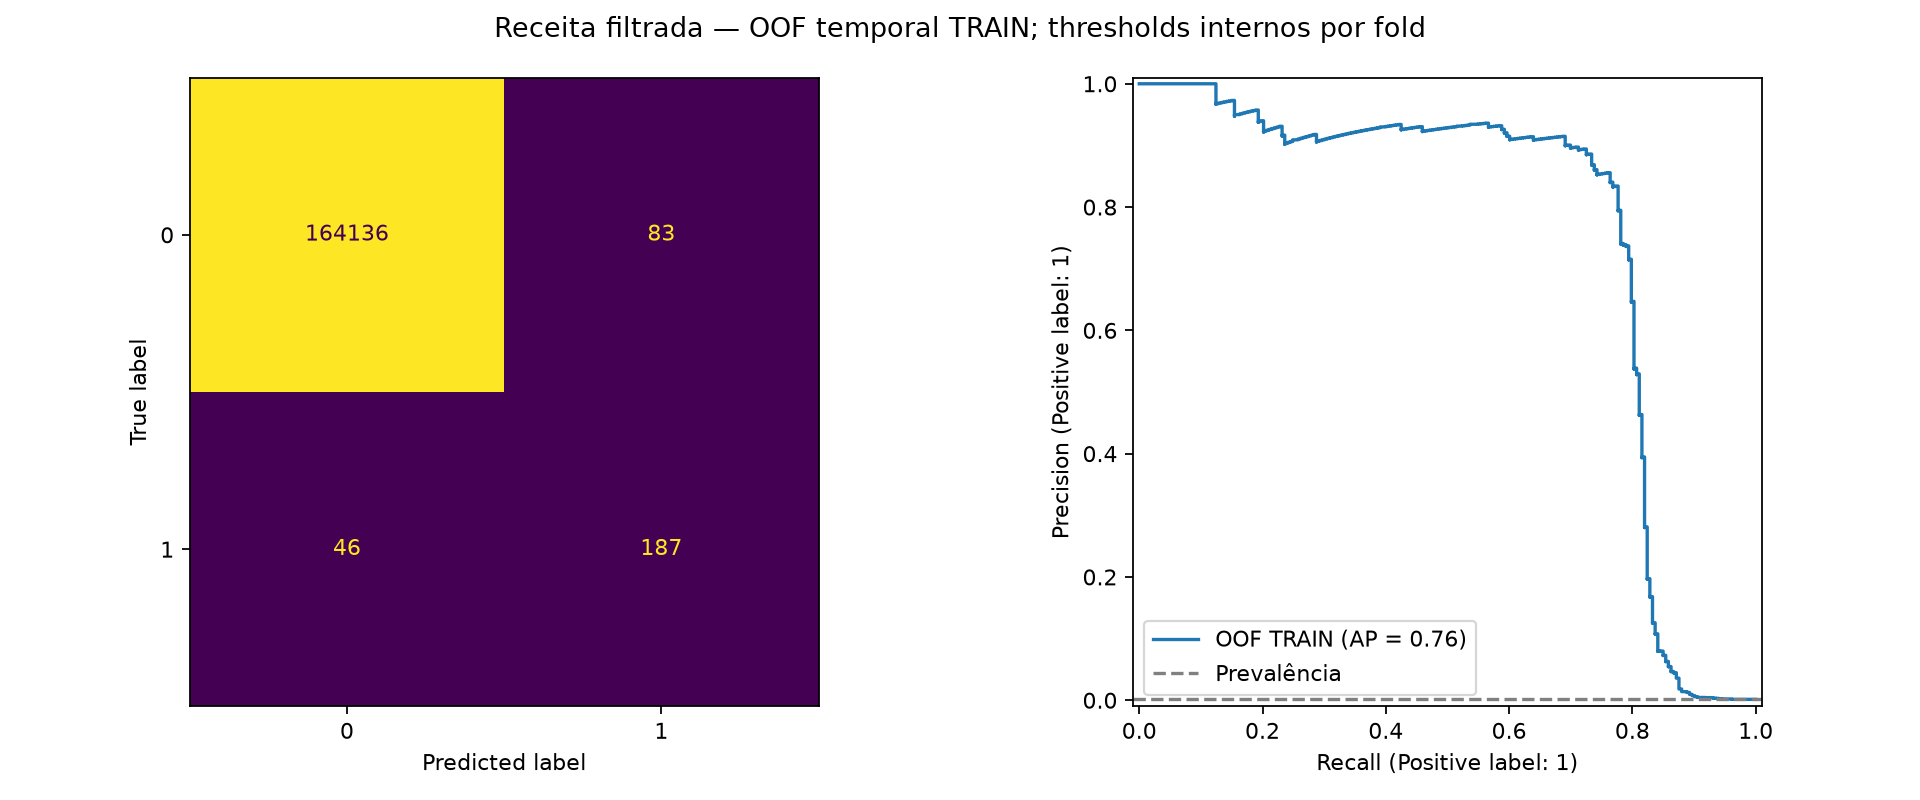

,Fold temporal,Faixa de valores,Quantidade,Fraudes confirmadas,TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas,TN: legítimas liberadas,Fraude na faixa (%),Recall da faixa (%),Precision da faixa (%),Falsos positivos entre legítimas (%),Alertas que eram falsos (%)
91,1,"(-1.057, -0.657]",5.077,2,0,2,2,5.073,0.0394%,0.00%,0.00%,0.04%,100.00%
92,1,"(-0.28, -0.12]",6.840,3,1,0,2,6.837,0.0439%,33.33%,100.00%,0.00%,0.00%
93,1,"(-inf, -1.057]",4.413,64,62,8,2,4.341,1.4503%,96.88%,88.57%,0.18%,11.43%
94,1,"(-0.443, -0.28]",5.488,3,0,0,3,5.485,0.0547%,0.00%,Não definido,0.00%,Não definido
95,1,"(-0.657, -0.443]",5.184,3,0,1,3,5.180,0.0579%,0.00%,0.00%,0.02%,100.00%
96,1,"(0.57, 0.89]",6.340,0,0,0,0,6.340,0.0000%,Não definido,Não definido,0.00%,Não definido
97,1,"(0.0218, 0.232]",6.192,2,1,0,1,6.190,0.0323%,50.00%,100.00%,0.00%,0.00%
98,1,"(0.89, inf]",6.289,1,0,0,1,6.288,0.0159%,0.00%,Não definido,0.00%,Não definido
99,1,"(-0.12, 0.0218]",7.214,3,0,0,3,7.211,0.0416%,0.00%,Não definido,0.00%,Não definido
100,1,"(0.232, 0.57]",5.552,3,0,0,3,5.549,0.0540%,0.00%,Não definido,0.00%,Não definido


Threshold final F2 no TRAIN: **0.7**. Artefato: **models/standardized_selected_pipeline.joblib**. Os CSVs têm todas as features; V10 é apenas o recorte exibido acima.

In [12]:
display_readable(table("ablation_threshold_comparison.csv"))
display_readable(table("ablation_threshold_folds.csv"))
figure("ablation_oof_pr_confusion.png")
category_errors = table("category_error_metrics.csv")
display_readable(category_errors.loc[
    category_errors.feature.eq("V10"),
    ["fold", "bin", "count", "fraud_count", "tp", "fp", "fn", "tn",
     "fraud_rate_pct", "recall_pct", "precision_pct",
     "false_positive_rate_pct", "false_alert_share_pct"]
])
display(Markdown(
    f"Threshold final F2 no TRAIN: **{ablation_selection['threshold']:g}**. "
    "Artefato: **models/standardized_selected_pipeline.joblib**. "
    "Os CSVs têm todas as features; V10 é apenas o recorte exibido acima."
))

## Rodada F3 — mais ênfase em Recall, somente no TRAIN
F3 usa beta=3: **10TP/(10TP+9FN+FP)**. Dá mais peso ao Recall que F2,
mas ainda penaliza falsos positivos. Não garante ganho em períodos futuros.

A mesma grade interna de GridSearchCV foi reponderada com F3 a partir das
contagens já calculadas; isso equivale ao scorer F-beta com beta=3 sobre as
mesmas previsões, sem repetir os fits internos. Cada threshold é escolhido
somente na janela interna anterior à validação externa.

Nas janelas externas em que o threshold mudou, os modelos foram reconstruídos
com as mesmas features/receita e suas contagens F2 foram conferidas contra as
originais antes de avaliar F3. Quando o threshold não mudou, os resultados
externos foram reutilizados. A família/receita foi escolhida em rodadas anteriores:
a avaliação é condicionada à seleção e ao reuso do TRAIN.

**TEST não foi reavaliado.** F3 foi escolhido depois de observar o TEST anterior;
a confirmação independente exigirá outro período.

,Política de threshold,Recall (%),Recall desvio (p.p.),Precision (%),Precision desvio (p.p.),F1 (%),F2 (%),F3 (%),FP: falsos alertas,FN: fraudes não detectadas
0,gridsearch_f2,79.41%,4.67 p.p.,72.24%,12.45 p.p.,75.02%,77.41%,78.36%,"27,6667","15,3333"
1,gridsearch_f3,80.20%,4.00 p.p.,51.61%,19.20 p.p.,61.46%,70.75%,74.99%,"58,3333","14,6667"


,Fold temporal,Política de threshold,Limiar de alerta,Recall (%),Precision (%),F2 (%),F3 (%),TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas
0,1,gridsearch_f2,"0,3000",76.19%,85.33%,77.86%,77.02%,64,11,20
1,2,gridsearch_f2,"0,3000",84.76%,60.54%,78.48%,81.50%,89,58,16
2,3,gridsearch_f2,"0,4500",77.27%,70.83%,75.89%,76.58%,34,14,10
3,1,gridsearch_f3,"0,1250",78.57%,64.71%,75.34%,76.92%,66,36,18
4,2,gridsearch_f3,"0,3000",84.76%,60.54%,78.48%,81.50%,89,58,16
5,3,gridsearch_f3,"0,2250",77.27%,29.57%,58.42%,66.54%,34,81,10


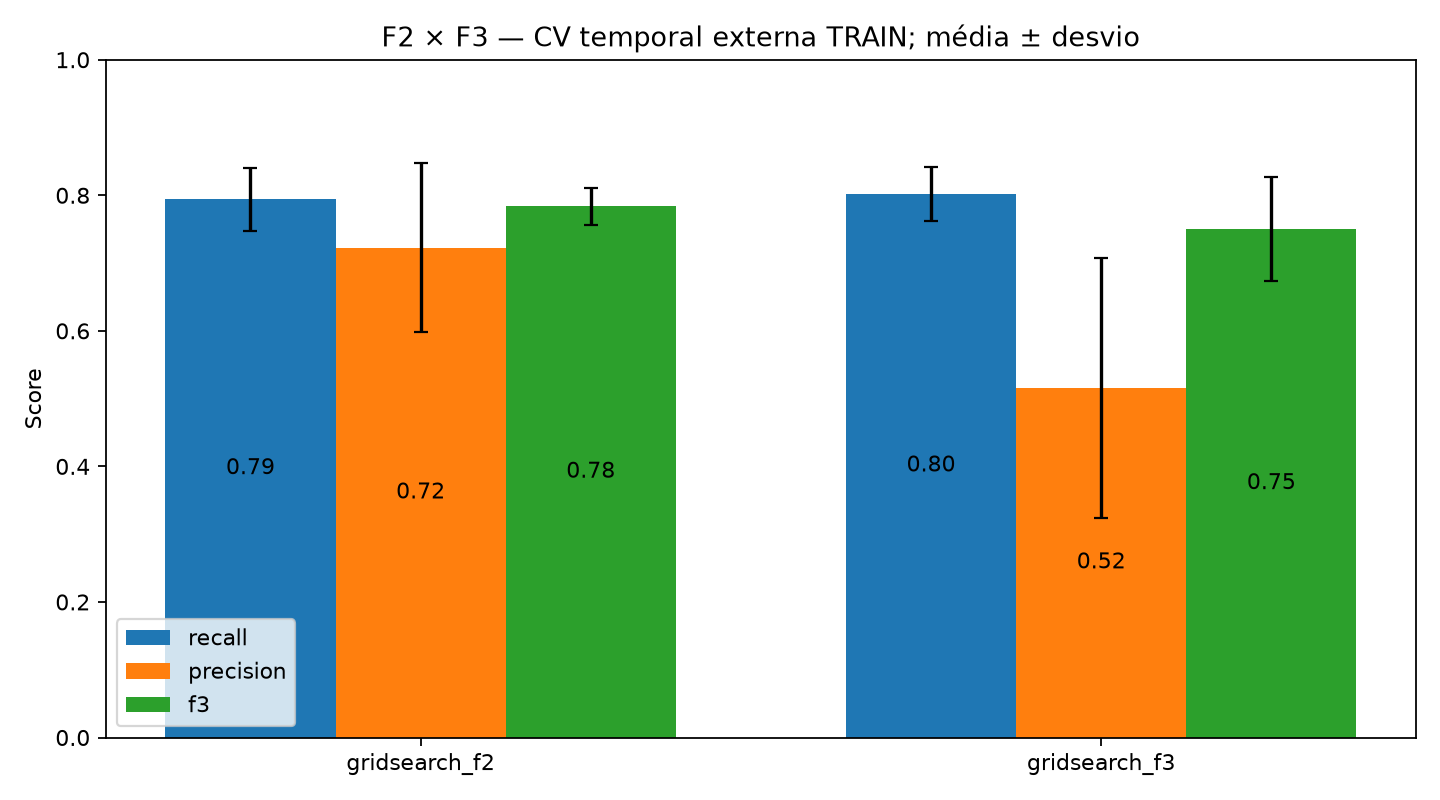

,fold,threshold_f2,threshold_f3,fit_time_max,validation_time_min,validation_time_max,method
0,1,0.30,0.125,42612.0,42613.0,69254.0,Refit no treino externo; contagens F2 reproduz...
1,2,0.30,0.300,69254.0,69255.0,108793.0,Reuso de métricas externas: mesmo modelo e mes...
2,3,0.45,0.225,108793.0,108799.0,138230.0,Refit no treino externo; contagens F2 reproduz...


Threshold final: **0.5** para F3, contra **0.7** para F2. O novo artefato é **models/recall_f3_pipeline.joblib**. A CV mede a política de ajuste com limiares próprios por fold, não o limiar final isoladamente.

Recall: **79.41% → 80.20%**. Precision: **72.24% → 51.61%**. F3 externo: **0.7836 → 0.7499**.

**F3 não apresentou vantagem validada nesta rodada.** O ganho pequeno de Recall veio com forte queda de Precision e piora do próprio F3 externo. O modelo F2 continua preservado.

In [13]:
f3_selection = json.loads(
    (EXPERIMENTS / "f3_selection.json").read_text(encoding="utf-8")
)
display_readable(table("f3_comparison.csv")[
    ["policy", "recall", "recall_std", "precision", "precision_std",
     "f1", "f2", "f3", "fp", "fn"]
])
display_readable(table("f3_outer_folds.csv")[
    ["fold", "policy", "threshold", "recall", "precision", "f2", "f3", "tp", "fp", "fn"]
])
figure("f3_comparison.png")
display(pd.read_csv(EXPERIMENTS / "f3_fold_manifest.csv"))
display(Markdown(
    f"Threshold final: **{f3_selection['threshold']:g}** para F3, "
    f"contra **{f3_selection['previous_f2_threshold']:g}** para F2. "
    "O novo artefato é **models/recall_f3_pipeline.joblib**. "
    "A CV mede a política de ajuste com limiares próprios por fold, "
    "não o limiar final isoladamente."
))

# Interpreta a validação externa, não o score interno que escolheu o limiar.
f3_comparison = table("f3_comparison.csv").set_index("policy")
f2_policy = f3_comparison.loc["gridsearch_f2"]
f3_policy = f3_comparison.loc["gridsearch_f3"]
display(Markdown(
    f"Recall: **{f2_policy.recall:.2%} → {f3_policy.recall:.2%}**. "
    f"Precision: **{f2_policy.precision:.2%} → {f3_policy.precision:.2%}**. "
    f"F3 externo: **{f2_policy.f3:.4f} → {f3_policy.f3:.4f}**."
))
if f3_policy.f3 <= f2_policy.f3:
    display(Markdown(
        "**F3 não apresentou vantagem validada nesta rodada.** "
        "O ganho pequeno de Recall veio com forte queda de Precision e "
        "piora do próprio F3 externo. O modelo F2 continua preservado."
    ))


### Seleção final na janela interna do TRAIN
Os scores abaixo são de seleção, não de avaliação independente. O pipeline já
treinado permanece idêntico; o novo artefato altera somente o limiar de decisão.
Os resultados históricos de TEST continuam pertencendo ao threshold 0,70.

In [14]:
display_readable(table("f3_final_grid.csv")[
    ["threshold", "recall", "precision", "f2", "f3", "tp", "fp", "fn"]
])
display(f3_selection["limitations"])

,Limiar de alerta,Recall (%),Precision (%),F2 (%),F3 (%),TP: fraudes detectadas,FP: falsos alertas,FN: fraudes não detectadas
0,"0,0000",100.00%,0.07%,0.37%,0.73%,39,52.969,0
1,"0,0001",100.00%,0.07%,0.37%,0.74%,39,52.621,0
2,"0,0003",100.00%,0.08%,0.40%,0.80%,39,48.224,0
3,"0,0010",100.00%,0.11%,0.55%,1.10%,39,35.055,0
4,"0,0030",100.00%,0.16%,0.78%,1.55%,39,24.691,0
5,"0,0050",100.00%,0.19%,0.96%,1.89%,39,20.211,0
6,"0,0100",97.44%,0.29%,1.43%,2.81%,38,13.113,1
7,"0,0200",94.87%,0.51%,2.51%,4.89%,37,7.175,2
8,"0,0300",92.31%,0.84%,4.04%,7.74%,36,4.267,3
9,"0,0500",87.18%,1.65%,7.67%,14.10%,34,2.026,5


['F3 escolhido após observar TEST anterior; este não serve como confirmação independente.',
 'Thresholds selecionados só nas janelas internas TRAIN; avaliação externa condicionada à receita.',
 'Média externa avalia a política de ajuste, não o threshold final isolado.',
 'Reuso de TRAIN ao longo das rodadas pode favorecer conclusões otimistas.',
 'F3 favorece Recall sem garantir aumento em dados novos ou custo ótimo.']

## TEST histórico — primeira rodada (XGBoost, threshold 0,5)
Esta seção é a única que mostra resultados de TEST. O último período mantém sua
prevalência original, sem SMOTE/undersampling. Não há comparação de candidatos no TEST.
A base histórica já havia sido explorada no projeto antigo: o protocolo corrigido é
retrospectivo e não equivale a um estudo prospectivo. Não use esta seção para retuning.

**Este TEST pertence ao XGBoost sem reamostragem da primeira rodada.**
As novas versões com threshold ajustado e Random Forest filtrada não foram
avaliadas novamente nele. Os resultados abaixo não devem ser atribuídos ao novo
artefato standardized_selected_pipeline.joblib.

,Receita,Origem,rows,positives,AP (score),F1 (%),Recall (%),Precision (%),ROC-AUC (score),Balanced Accuracy (%),Especificidade (%),Log Loss,Brier score,TN: legítimas liberadas,FP: falsos alertas,FN: fraudes não detectadas,TP: fraudes detectadas,Limiar de alerta
0,xgboost__none,TEST temporal final,73.434,97,"0,8062",80.47%,70.10%,94.44%,"0,9871",85.05%,99.99%,"0,0024","0,0004",73.333,4,29,68,"0,5000"


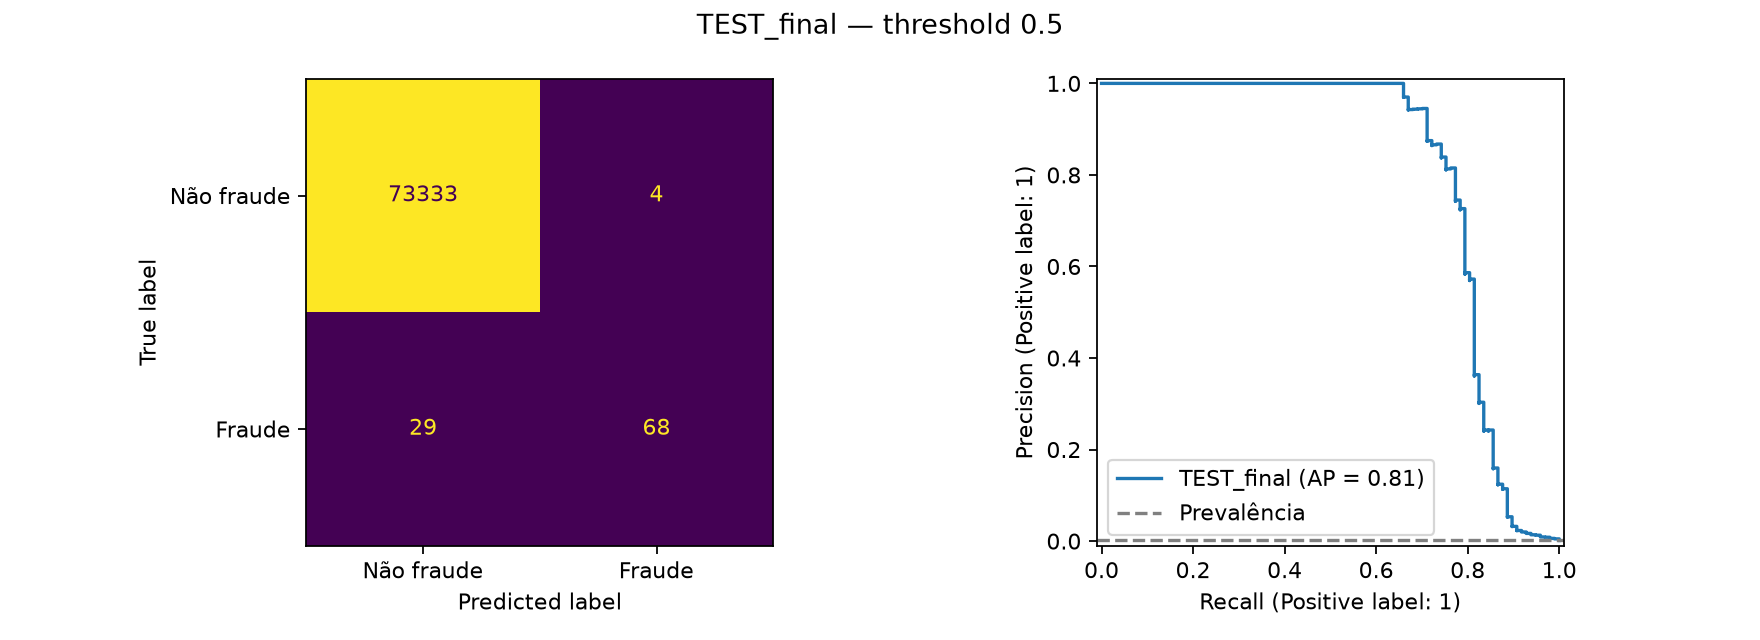

,time_interval,rows,AP (score),F1 (%),Recall (%),Precision (%),ROC-AUC (score),Balanced Accuracy (%),Especificidade (%),Log Loss,Brier score,TN: legítimas liberadas,FP: falsos alertas,FN: fraudes não detectadas,TP: fraudes detectadas,Limiar de alerta
0,"(138199.442, 146873.5]",20.528,"0,8177",83.33%,74.07%,95.24%,"0,9849",87.03%,100.00%,"0,0023","0,0004",20.500,1,7,20,"0,5000"
1,"(146873.5, 155513.0]",20.079,"0,8953",84.85%,73.68%,100.00%,"0,9937",86.84%,100.00%,"0,0023","0,0004",20.041,0,10,28,"0,5000"
2,"(155513.0, 164152.5]",18.672,"0,7854",81.08%,71.43%,93.75%,"0,9924",85.71%,99.99%,"0,0021","0,0003",18.650,1,6,15,"0,5000"
3,"(164152.5, 172792.0]",14.155,"0,5238",55.56%,45.45%,71.43%,"0,9606",72.72%,99.99%,"0,0031","0,0005",14.142,2,6,5,"0,5000"


No TEST, **xgboost__none** obteve AP **0.8062**, Recall **0.701**, Precision **0.944** e F1 **0.805** no threshold 0.5. Foram **29 FN** e **4 FP**. Sem custos de erro ou capacidade de revisão, não se conclui adequação operacional.

In [15]:
test = json.loads((METRICS / "test_metrics.json").read_text(encoding="utf-8"))
display_readable(pd.DataFrame([test]))
figure("TEST_final_diagnostics.png")
display_readable(table("test_time_segments.csv"))
display(Markdown(f"No TEST, **{test['model']}** obteve AP **{test['average_precision']:.4f}**, Recall **{test['recall']:.3f}**, Precision **{test['precision']:.3f}** e F1 **{test['f1']:.3f}** no threshold {test['threshold']}. Foram **{test['fn']} FN** e **{test['fp']} FP**. Sem custos de erro ou capacidade de revisão, não se conclui adequação operacional."))

### Limites da avaliação final
Apenas dois dias e poucas fraudes no TEST limitam a precisão e a generalização.
Não há intervalos formais de incerteza nesta rodada; a dispersão de CV não é intervalo
de confiança do TEST. Avaliação em mais períodos e bootstrap em blocos, com cobertura
temporal suficiente, são próximos passos. O PCA original e separação por cliente
não puderam ser auditados. Probabilidades não foram calibradas. Nenhuma alegação
de prontidão de produção decorre destes resultados.